# **MUHAMMAD TAYYAB IFTIKHAR

## **APPLYING INCEPTIONNET FOR FACIAL CLUSTRING DATA**

### **DATASET OVERVIEW**

The given appears to be a large-scale facial recognition dataset designed for training deep learning models for facial classification. Here's a breakdown of the key components:

**Training Set:**

*Size:* Over 140,000 images.

*Content:* 7,000 unique identities, with each identity having 20 images. These images are stored in separate folders, with each folder corresponding to a unique identity.

This Dataset will be used for training and as well as for validaion of my model.

**Test Set:**

*Size:* 35,000 images, with 5 images per identity. These images are randomly assigned a number between 1 and 35,000 for identification purposes.

*Content:* The test set contains no labels, so the model is required to predict the identities based on the facial features from the images.

This dataset will use for prediction after the training the model will predict labels on this dataset.

**INSTALLING FACENET-PYTORCH FOR INCEPTIONNET**

In [4]:
pip install facenet-pytorch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 60.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 87.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 84.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 755.6/755.6 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 83.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 88.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2

**IMPORTING NECESSORY LIBRARIES AND PACKAGES**

In [ ]:
import os
import cv2
import random
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import DataLoader, Dataset
import torch
import torch.nn as nn
from tqdm import tqdm
from facenet_pytorch import InceptionResnetV1
import matplotlib.pyplot as plt
import pandas as pd
from torchvision import transforms
from PIL import Image

### **LOADING THE DATASET AND UNZIPPING IT**

I used the Kaggle API to download the dataset by uploading your kaggle.json key, authenticating, and then downloading and unzipping the dataset into a dataset folder

In [2]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"tayyabiftikhar","key":"6bbb086b7374e272b281d21866b36200"}'}

In [5]:
!mkdir -p /root/.config/kaggle
!mv kaggle.json /root/.config/kaggle/
!chmod 600 /root/.config/kaggle/kaggle.json


In [6]:
!kaggle competitions download -c face-classification-deep-learning-cs-405

In [7]:
!unzip face-classification-deep-learning-cs-405.zip -d dataset

Streaming output truncated to the last 5000 lines.
  inflating: dataset/dataset/train/n008922/0001_01.jpg  
  inflating: dataset/dataset/train/n008922/0007_02.jpg  
  inflating: dataset/dataset/train/n008922/0011_01.jpg  
  inflating: dataset/dataset/train/n008922/0015_01.jpg  
  inflating: dataset/dataset/train/n008922/0019_01.jpg  
  inflating: dataset/dataset/train/n008922/0025_01.jpg  
  inflating: dataset/dataset/train/n008922/0037_01.jpg  
  inflating: dataset/dataset/train/n008922/0044_01.jpg  
  inflating: dataset/dataset/train/n008922/0070_01.jpg  
  inflating: dataset/dataset/train/n008922/0093_01.jpg  
  inflating: dataset/dataset/train/n008922/0123_02.jpg  
  inflating: dataset/dataset/train/n008922/0129_01.jpg  
  inflating: dataset/dataset/train/n008922/0146_01.jpg  
  inflating: dataset/dataset/train/n008922/0154_01.jpg  
  inflating: dataset/dataset/train/n008922/0183_01.jpg  
  inflating: dataset/dataset/train/n008922/0185_01.jpg  
  inflating: dataset/dataset/train/n0

### **PREPARE TRANSFORM AND LOAD THE DATASET**

I have split the data here in 90:10 for train and validaiton respectivelt and ensures that from each class 2 images should be part of the validation for this i have used for loop for better generalization.

In [8]:
# CUSTOM DATASET CLASS TO LOAD IMAGES AND APPLY TRANSFORMATIONS FOR TRAINING
class FaceDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image=image)['image']
        return image, label

dataset_root = '/content/dataset/dataset/train'
class_names = sorted(os.listdir(dataset_root))

class_to_idx = {cls_name: i for i, cls_name in enumerate(class_names)}

# COLLECT ALL IMAGE PATHS AND THEIR CORRESPONDING LABELS
all_samples = []
for cls_name in class_names:
    cls_folder = os.path.join(dataset_root, cls_name)
    for img_name in os.listdir(cls_folder):
        img_path = os.path.join(cls_folder, img_name)
        label = class_to_idx[cls_name]
        all_samples.append((img_path, label))

train_samples = []
val_samples = []


# SPLIT EACH CLASS INTO TRAIN AND VALIDATION SAMPLES (TAKE 2 FOR VALIDATION)
for cls_name in class_names:
    class_samples = [sample for sample in all_samples if sample[1] == class_to_idx[cls_name]]
    random.shuffle(class_samples)
    val_samples.extend(class_samples[:2])
    train_samples.extend(class_samples[2:])


In below Dataloaders are used to load the data in small batches because storing the entire dataset at once would take up too much memory. Loading data in chunks makes it easier to work with large datasets that can't fit in memory all at once and also ensures that dataset shuffle before reloading before every epoch

In [9]:
# APPLYING DATA AUGMENTATION TECHNIQUES
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, p=0.3),
    A.RandomBrightnessContrast(p=0.2),
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

test_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

train_dataset = FaceDataset(train_samples, transform=train_transform)
val_dataset = FaceDataset(val_samples, transform=test_transform)

BATCH_SIZE = 128

# CREATING DATALOADERS FOR TRAINING AND VALIDATION
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Training set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_dataset)}")
print(f"Class mapping: {class_to_idx}")


Training set size: 126000
Validation set size: 14000
Class mapping: {'n000001': 0, 'n000002': 1, 'n000003': 2, 'n000004': 3, 'n000005': 4, 'n000008': 5, 'n000011': 6, 'n000012': 7, 'n000013': 8, 'n000014': 9, 'n000015': 10, 'n000016': 11, 'n000017': 12, 'n000018': 13, 'n000019': 14, 'n000020': 15, 'n000021': 16, 'n000022': 17, 'n000023': 18, 'n000024': 19, 'n000025': 20, 'n000026': 21, 'n000027': 22, 'n000029': 23, 'n000030': 24, 'n000031': 25, 'n000034': 26, 'n000035': 27, 'n000036': 28, 'n000037': 29, 'n000038': 30, 'n000040': 31, 'n000041': 32, 'n000042': 33, 'n000043': 34, 'n000044': 35, 'n000045': 36, 'n000046': 37, 'n000047': 38, 'n000048': 39, 'n000049': 40, 'n000050': 41, 'n000051': 42, 'n000052': 43, 'n000053': 44, 'n000054': 45, 'n000055': 46, 'n000056': 47, 'n000057': 48, 'n000058': 49, 'n000059': 50, 'n000060': 51, 'n000061': 52, 'n000062': 53, 'n000063': 54, 'n000066': 55, 'n000067': 56, 'n000068': 57, 'n000069': 58, 'n000070': 59, 'n000071': 60, 'n000074': 61, 'n000075': 

**VISUALIZING THE DATA:**

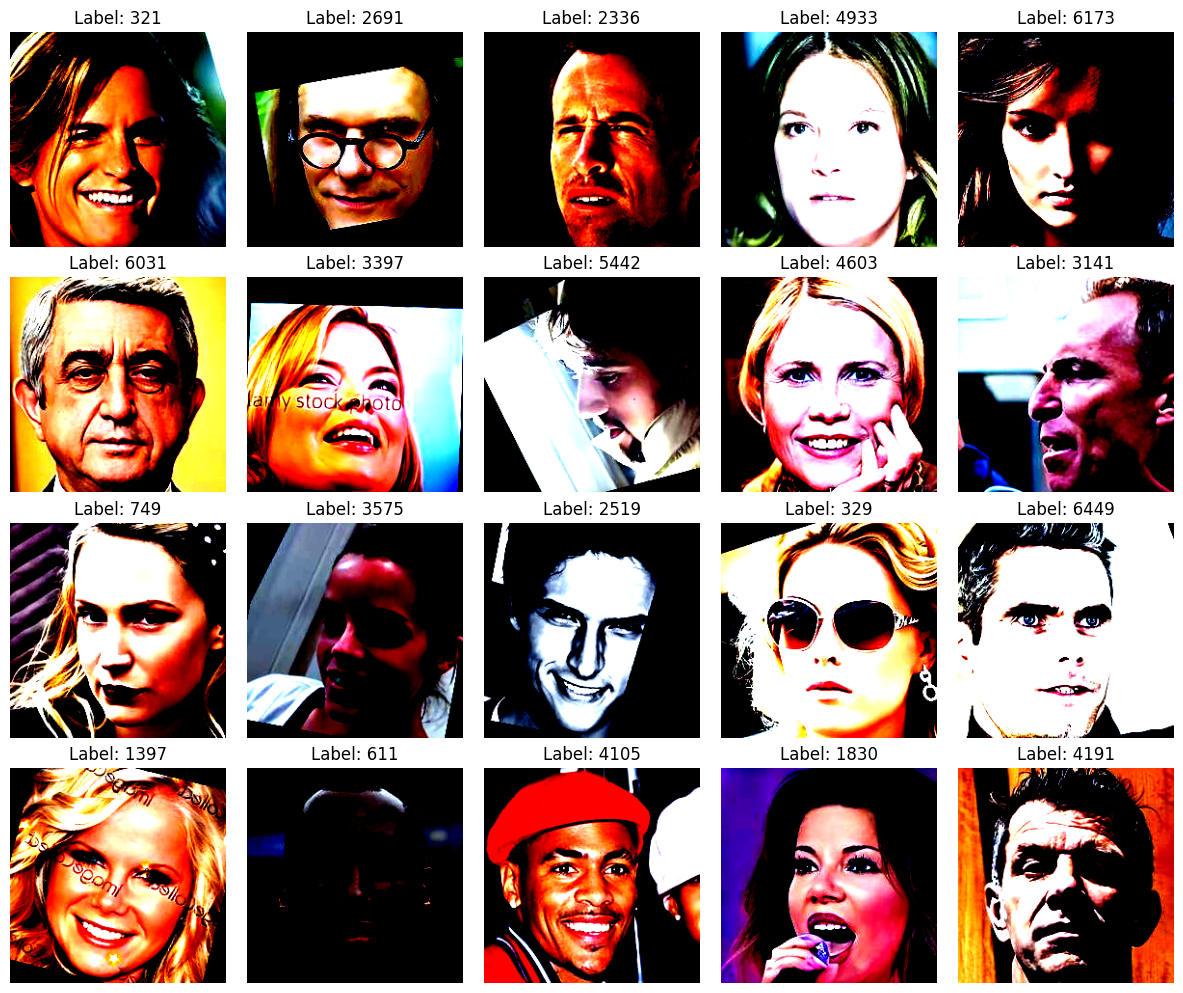

In [11]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
axes = axes.flatten()

for i in range(20):
    image = images[i].numpy().transpose(1, 2, 0)
    axes[i].imshow(image)
    axes[i].axis('off')
    axes[i].set_title(f"Label: {labels[i].item()}")

plt.tight_layout()
plt.show()


### **MODEL TRAINING AND EVALUATION**

I have finetuned the inception resnet and having 90% of its layer freezed and replace the final classifier layer with 7000 classes and do not add any extra layers as it reduces accuracies

In [3]:
# CHECK GPU AVAILABILITY
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# INITIALIZE THE MODEL
num_classes = len(class_to_idx)
model = InceptionResnetV1(pretrained='vggface2', classify=True, num_classes=num_classes).to(device)

# FREEZE INITIAL LAYERS
layers = list(model.children())
total_layers = len(list(model.parameters()))
freeze_until = int(0.9 * total_layers)

for i, param in enumerate(model.parameters()):
    param.requires_grad = False if i < freeze_until else True

# DEFINE LOSS AND OPTIMIZER
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-5)

def accuracy(outputs, labels):
    _, preds = torch.max(outputs, 1)
    return (preds == labels).float().mean()

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []


  0%|          | 0.00/107M [00:00<?, ?B/s]

Epoch [1/5] Training: 100%|██████████| 985/985 [05:58<00:00,  2.75it/s, acc=0.312, loss=6.11]



Epoch 1/5
Train Loss: 7.3928 | Train Acc: 0.1354
Val   Loss: 5.7141 | Val   Acc: 0.4932


Epoch [2/5] Training: 100%|██████████| 985/985 [05:58<00:00,  2.75it/s, acc=0.75, loss=3.35]



Epoch 2/5
Train Loss: 4.5327 | Train Acc: 0.6136
Val   Loss: 3.2457 | Val   Acc: 0.8088


Epoch [3/5] Training: 100%|██████████| 985/985 [05:58<00:00,  2.75it/s, acc=0.854, loss=1.95]



Epoch 3/5
Train Loss: 2.4530 | Train Acc: 0.8415
Val   Loss: 1.7528 | Val   Acc: 0.8774


Epoch [4/5] Training: 100%|██████████| 985/985 [05:58<00:00,  2.75it/s, acc=0.896, loss=1.44]



Epoch 4/5
Train Loss: 1.3733 | Train Acc: 0.8964
Val   Loss: 1.2067 | Val   Acc: 0.8927


Epoch [5/5] Training: 100%|██████████| 985/985 [05:58<00:00,  2.75it/s, acc=0.917, loss=0.95]



Epoch 5/5
Train Loss: 0.9132 | Train Acc: 0.9161
Val   Loss: 0.9362 | Val   Acc: 0.8969


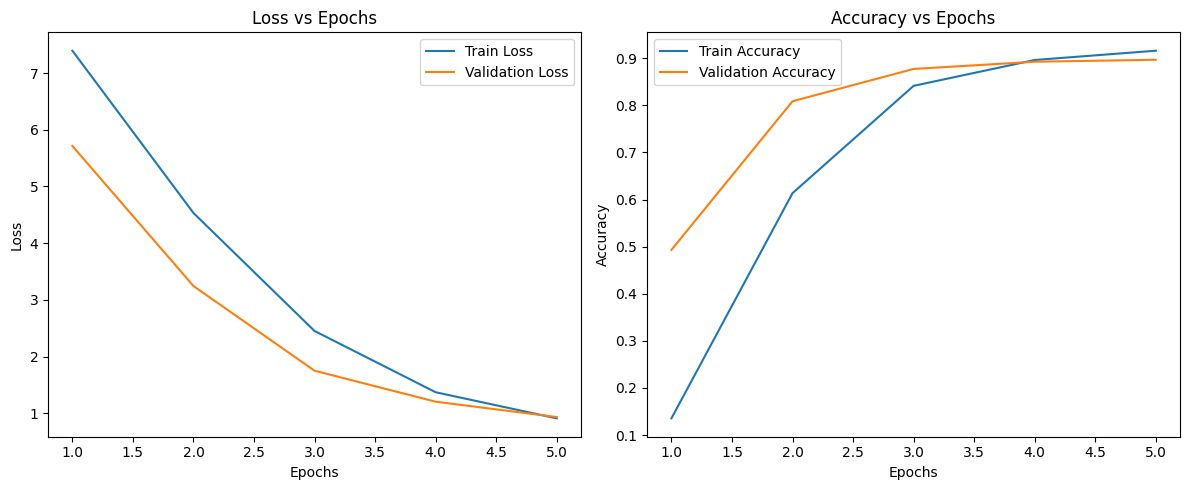

In [11]:
num_epochs = 5
for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_acc = 0

    # SHUFFLE TRAINING DATA
    train_loader.dataset.samples = random.sample(train_loader.dataset.samples, len(train_loader.dataset.samples))

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{num_epochs}] Training")
    for images, labels in loop:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        acc = accuracy(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_acc += acc.item()

        loop.set_postfix(loss=loss.item(), acc=acc.item())

    train_losses.append(train_loss / len(train_loader))
    train_accuracies.append(train_acc / len(train_loader))

    model.eval()
    val_loss = 0
    val_acc = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            acc = accuracy(outputs, labels)

            val_loss += loss.item()
            val_acc += acc.item()

    val_losses.append(val_loss / len(val_loader))
    val_accuracies.append(val_acc / len(val_loader))

    # PRINT EPOCH RESULTS
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss/len(train_loader):.4f} | Train Acc: {train_acc/len(train_loader):.4f}")
    print(f"Val   Loss: {val_loss/len(val_loader):.4f} | Val   Acc: {val_acc/len(val_loader):.4f}")

# Visualization of Training and Validation Curves
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 5))

# PLOT LOSS CURVE
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# PLOT ACCURACY CURVE
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label='Train Accuracy')
plt.plot(epochs, val_accuracies, label='Validation Accuracy')
plt.title('Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


The model shows significant improvement over the 5 epochs. In the first epoch, the training accuracy was low (13.54%), with a large loss (7.39), but by the fifth epoch, training accuracy rose to 91.61%, with a corresponding decrease in training loss to 0.91. Validation accuracy followed a similar upward trend, from 49.32% in epoch 1 to 89.69% in epoch 5, indicating the model's ability to generalize well. The training accuracy is higher than validation accuracy, suggesting potential overfitting, but the gap is not excessively large, indicating good model performance overall.

### **HAVING PREDICTIONS ON ACTUAL TEST DATA**

In [12]:
test_dir = '/content/dataset/dataset/test'

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
])

test_images = [f for f in os.listdir(test_dir) if f.endswith('.jpg')]
test_samples = [os.path.join(test_dir, img) for img in test_images]

class TestDataset(torch.utils.data.Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, img_path

test_dataset = TestDataset(test_samples, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

model.eval()

predictions = []

with torch.no_grad():
    for images, img_paths in tqdm(test_loader, desc="Predicting test set"):
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        predicted_labels = [list(class_to_idx.keys())[list(class_to_idx.values()).index(pred.item())] for pred in preds]
        for img_path, label in zip(img_paths, predicted_labels):
            img_name = os.path.basename(img_path)
            predictions.append((img_name, label))

df = pd.DataFrame(predictions, columns=['image_name', 'label'])
df.to_csv('/content/sample_submission_inception_resnet.csv', index=False)

print("Predictions saved to inception_resnet.csv")


Predicting test set: 100%|██████████| 274/274 [02:29<00:00,  1.83it/s]

Predictions saved to inception_resnet.csv
